<p style="text-align:center">
    <a href="https://skills.network" target="_blank">
    <img src="https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/assets/logos/SN_web_lightmode.png" width="200" alt="Skills Network Logo"  />
    </a>
</p>


# **Finding Outliers | Understanding Unusual Salary Values**
**IBM Skills Network guided lab | Personalized portfolio edition**


### Project Overview
When I look at salary data, I don't want to rely only on an average. A small number of unusually high values can pull that average upward and make it harder to understand what a typical respondent earns.

In this notebook, I explore a developer survey, look at the industries represented, and use two statistical approaches to flag unusual compensation values. I then see what happens when those records are excluded and explore the relationship between age and professional coding experience.

**Question guiding the project:** How do unusual salary values affect what we see in the data, and what should we check before removing them?

**My approach:** Load the survey → Explore industries → Flag high salaries → Apply the IQR rule → Compare the remaining data → Explore correlations.

**Tools and skills:** Python, Pandas, Matplotlib, Seaborn, descriptive statistics, outlier detection, and correlation analysis.

*This is an IBM Skills Network guided exercise. I have preserved the original lab and added explanations and reflections to make the analysis accessible to non-technical readers.*

Estimated time needed: **30** minutes


In this lab, you will work with a cleaned dataset to perform exploratory data analysis or EDA. 
You will explore the distribution of key variables and focus on identifying outliers in this lab.


### Objectives


In this lab, you will perform the following:
-  Analyze the distribution of key variables in the dataset.
-  Identify and remove outliers using statistical methods.
-  Perform relevant statistical and correlation analysis.

#### Install and import the required libraries


In [1]:
!pip install pandas
!pip install matplotlib
!pip install seaborn

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

<h3>Step 1: Load and Explore the Dataset</h3>


Load the dataset into a DataFrame and examine the structure of the data.<br>
Before I start looking for unusual numbers, I want to understand the dataset. Loading the CSV into a DataFrame gives me a table I can inspect and analyze. The first few rows show what a survey response looks like and which questions are available. A preview is useful for orientation, but it doesn't tell us whether the entire survey represents all developers.

In [2]:
file_url = "https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/n01PQ9pSmiRX6520flujwQ/survey-data.csv"

#Create the dataframe
df = pd.read_csv(file_url)

#Display the top 10 records
df.head()

,ResponseId,MainBranch,Age,Employment,RemoteWork,Check,CodingActivities,EdLevel,LearnCode,LearnCodeOnline,...,JobSatPoints_6,JobSatPoints_7,JobSatPoints_8,JobSatPoints_9,JobSatPoints_10,JobSatPoints_11,SurveyLength,SurveyEase,ConvertedCompYearly,JobSat
0,1,I am a developer by profession,Under 18 years old,"Employed, full-time",Remote,Apples,Hobby,Primary/elementary school,Books / Physical media,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2,I am a developer by profession,35-44 years old,"Employed, full-time",Remote,Apples,Hobby;Contribute to open-source projects;Other...,"Bachelor’s degree (B.A., B.S., B.Eng., etc.)",Books / Physical media;Colleague;On the job tr...,Technical documentation;Blogs;Books;Written Tu...,...,0.0,0.0,0.0,0.0,0.0,0.0,NaN,NaN,NaN,NaN
2,3,I am a developer by profession,45-54 years old,"Employed, full-time",Remote,Apples,Hobby;Contribute to open-source projects;Other...,"Master’s degree (M.A., M.S., M.Eng., MBA, etc.)",Books / Physical media;Colleague;On the job tr...,Technical documentation;Blogs;Books;Written Tu...,...,NaN,NaN,NaN,NaN,NaN,NaN,Appropriate in length,Easy,NaN,NaN
3,4,I am learning to code,18-24 years old,"Student, full-time",NaN,Apples,NaN,Some college/university study without earning ...,"Other online resources (e.g., videos, blogs, f...",Stack Overflow;How-to videos;Interactive tutorial,...,NaN,NaN,NaN,NaN,NaN,NaN,Too long,Easy,NaN,NaN
4,5,I am a developer by profession,18-24 years old,"Student, full-time",NaN,Apples,NaN,"Secondary school (e.g. American high school, G...","Other online resources (e.g., videos, blogs, f...",Technical documentation;Blogs;Written Tutorial...,...,NaN,NaN,NaN,NaN,NaN,NaN,Too short,Easy,NaN,NaN


<h3>Step 2: Plot the Distribution of Industry</h3>


Explore how respondents are distributed across different industries.
- Plot a bar chart to visualize the distribution of respondents by industry.
- Highlight any notable trends.

The longer the bar, the more respondents selected that industry. This is a picture of who answered this survey, not a measure of how many developers work in each industry worldwide. Missing industry answers also matter when interpreting the chart.

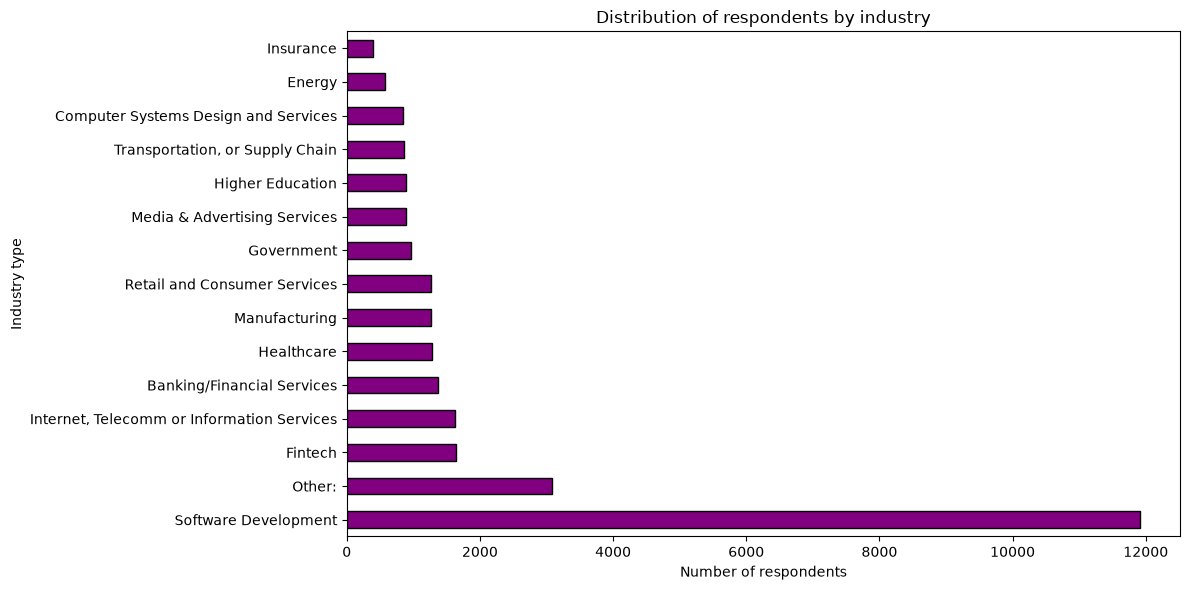

In [3]:
##Write your code here
plt.figure(figsize=(12, 6))
df['Industry'].value_counts().plot(kind='barh', color='purple', edgecolor='black')
plt.title('Distribution of respondents by industry')
plt.ylabel('Industry type')
plt.xlabel('Number of respondents')
plt.tight_layout()
plt.show()

<h3>Step 3: Identify High Compensation Outliers</h3>


Identify respondents with extremely high yearly compensation.
- Calculate basic statistics (mean, median, and standard deviation) for `ConvertedCompYearly`.
- Identify compensation values exceeding a defined threshold (e.g., 3 standard deviations above the mean).

In [4]:
##Write your code here
middle_salary = df['ConvertedCompYearly'].median()
df['ConvertedCompYearly'] = df['ConvertedCompYearly'].fillna(middle_salary)

average_salary = df['ConvertedCompYearly'].mean()
salary_variation = df['ConvertedCompYearly'].std()

print('Basic Salary Statistics')
print(f"Middle Salary: ${middle_salary:,.2f}")
print(f"Average Salary: ${average_salary:,.2f}")
print(f"Standard deviation: ${salary_variation:,.2f}")
print("-" * 30)

cutoff = average_salary + (3 * salary_variation)
unusual_high_earners = df[df['ConvertedCompYearly'] > cutoff]
print(f"Any salary above line is an outlier: ${cutoff:,.2f}")
print(f"Total number of unusually high salaries: {len(unusual_high_earners)}")

Basic Salary Statistics
Middle Salary: $65,000.00
Average Salary: $72,576.36
Standard deviation: $112,220.68
------------------------------
Any salary above line is an outlier: $409,238.40
Total number of unusually high salaries: 194

First, the code fills missing yearly compensation values with the median salary. Then it calculates the mean and standard deviation and flags salaries above mean + 3 standard deviations.

**Saved results:** The median is $65,000, the mean is approximately $72,576, and the standard deviation is approximately $112,221. The high-salary cutoff is approximately $409,238.

**Why this needs caution:** Filling missing salaries with the median changes the salary distribution and can affect both the mean and the standard deviation. The resulting cutoff describes the filled dataset, not just the salaries respondents actually reported. Also, compensation values should be checked for their currency and reporting basis before making broader comparisons.

<h3>Step 4: Detect Outliers in Compensation</h3>


Identify outliers in the `ConvertedCompYearly` column using the IQR method.
- Calculate the Interquartile Range (IQR).
- Determine the upper and lower bounds for outliers.
- Count and visualize outliers using a box plot.

Lower Bound: 65000.0
Upper Bound: 65000.0
Total outliers detected using IQR method: 23398

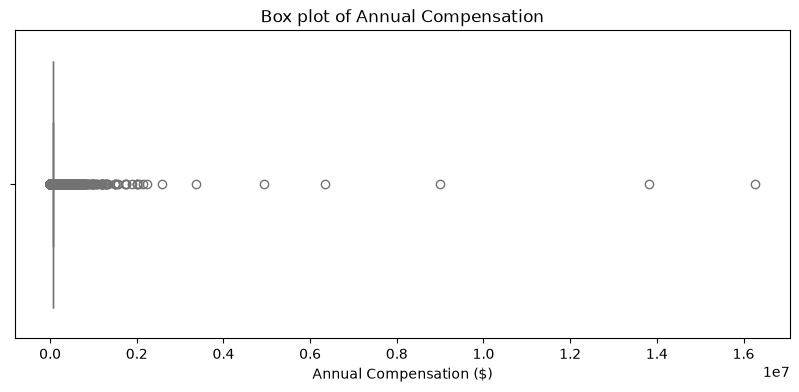

In [7]:
##Write your code here
Q1 = df['ConvertedCompYearly'].quantile(0.25)
Q3 = df['ConvertedCompYearly'].quantile(0.75)
IQR = Q3 - Q1
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

print("Lower Bound:", lower_bound)
print("Upper Bound:", upper_bound)

outliers_iqr = df[(df['ConvertedCompYearly'] < lower_bound) | (df['ConvertedCompYearly'] > upper_bound)]
print("Total outliers detected using IQR method:", len(outliers_iqr))

plt.figure(figsize=(10, 4))
sns.boxplot(x=df['ConvertedCompYearly'], color='lightgreen')
plt.title('Box plot of Annual Compensation')
plt.xlabel('Annual Compensation ($)')
plt.show()

**An important result from this notebook:** Both the lower and upper IQR bounds are $65,000, and the code flags 23,398 records as outliers. This happens because the median-filled values are so concentrated at $65,000 that the first and third quartiles coincide, making the IQR equal to zero.

**What this means:** The IQR rule here treats every salary different from $65,000 as an outlier. That's a warning that this approach, applied after median imputation, is not giving us a useful definition of unusually high or low compensation. I would examine the original non-missing salaries before deciding which records, if any, to exclude.

<h3>Step 5: Remove Outliers and Create a New DataFrame</h3>


Remove outliers from the dataset.

- Create a new DataFrame excluding rows with outliers in `ConvertedCompYearly`.
- Validate the size of the new DataFrame.


In [9]:
##Write your code here
df_cleaned = df[(df['ConvertedCompYearly'] >= lower_bound) & (df['ConvertedCompYearly'] <= upper_bound)].reset_index(drop=True)
print('Original DataFrame size:', df.shape)
print('Cleaned DataFrame size (outliers removed):', df_cleaned.shape)

Original DataFrame size: (65437, 114)
Cleaned DataFrame size (outliers removed): (42039, 114)

**Saved results:** The dataset goes from 65,437 rows to 42,039 rows-a reduction of 23,398.

Because both bounds equal $65,000, the remaining dataset contains only records with that compensation value, including many records that were filled with the median earlier. This is not a reliable salary-outlier-cleaned sample. I keep the original code to show the exercise, but I would not use this filtered dataset to make real salary recommendations.

<h3>Step 6: Correlation Analysis</h3>


Analyze the correlation between `Age` (transformed) and other numerical columns.
- Map the `Age` column to approximate numeric values.
- Compute correlations between `Age` and other numeric variables.
- Visualize the correlation matrix.

Correlation matrix:                      Age_numeric  YearsCodePro  ConvertedCompYearly
Age_numeric             1.000000      0.653053                  NaN
YearsCodePro            0.653053      1.000000                  NaN
ConvertedCompYearly          NaN           NaN                  NaN

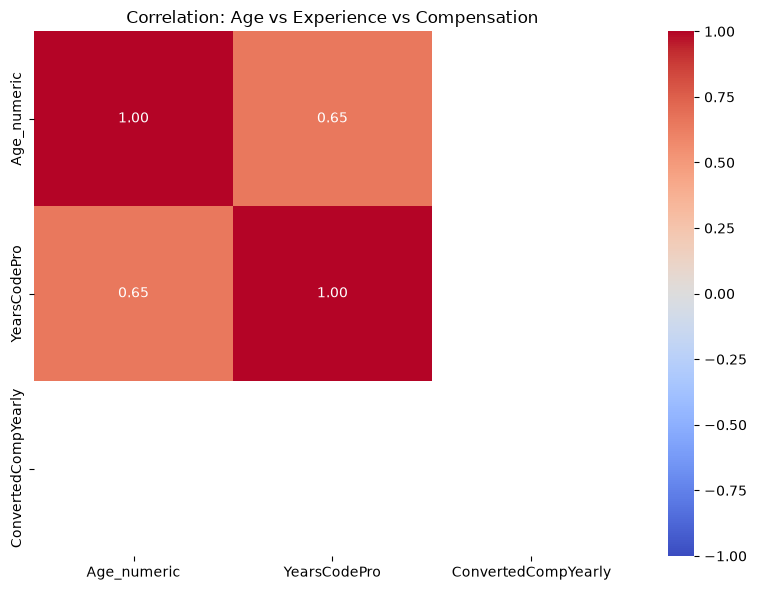

In [10]:
##Write your code here
# 1. Map text-based Age column ranges safely to numeric averages
age_map = {
    'Under 18 years old': 16,
    '18-24 years old': 21,
    '25-34 years old': 29,
    '35-44 years old': 39,
    '45-54 years old': 49,
    '55-64 years old': 59,
    '65 years or older': 68
}
df_cleaned['Age_numeric'] = df_cleaned['Age'].map(age_map).fillna(29)
df_cleaned['YearsCodePro'] = pd.to_numeric(df_cleaned['YearsCodePro'], errors='coerce').fillna(0)

numeric_cols = ['Age_numeric', 'YearsCodePro', 'ConvertedCompYearly']
correlation_matrix = df_cleaned[numeric_cols].corr()
print("Correlation matrix:", correlation_matrix)

plt.figure(figsize=(8, 6))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt=".2f", vmin=-1, vmax=1)
plt.title('Correlation: Age vs Experience vs Compensation')
plt.tight_layout()
plt.show()

**Saved result:** Age and professional coding experience have a correlation of about 0.65 in the filtered data. This suggests a moderately strong positive relationship in that particular subset.

**But there is a major limitation:** The salary column has only one value after filtering, so its correlations are undefined (NaN). Also, the earlier filtering changes which respondents remain, and age values are estimates from categories. I would avoid generalizing this result to the full survey.

### Key Findings and Takeaways
- The saved survey contains 65,437 responses and 114 columns.
- The median salary used to fill missing compensation is $65,000. A three-standard-deviation rule flags salaries above roughly $409,238 as unusually high.
- After median imputation, the IQR becomes zero, making the IQR-based outlier boundaries both equal to $65,000.
- The filtering step removes 23,398 records, but the result is not a meaningful cleaned salary distribution: it retains only the $65,000 values.
- In that filtered subset, age and professional coding experience show a correlation of approximately 0.65. Compensation correlations are undefined because salary no longer varies.

### Limitations and Next Steps
If I continued this analysis, I would keep missing salaries separate while detecting outliers, investigate extreme values rather than automatically delete them, compare the original and filtered distributions, and explain the effect of each cleaning choice. I would also use the full appropriate sample-not a constant-salary subset-when examining salary relationships.

### Skills Demonstrated
- Data exploration: Loading and inspecting survey records and industry counts.
- Descriptive statistics: Mean, median, standard deviation, quartiles, and IQR.
- Data visualization: Bar charts, box plots, and correlation heatmaps.
- Analytical judgment: Recognizing when a statistical rule produces a misleading result.
- Communication: Explaining limitations without overstating what the data proves.

<h3> Summary </h3>


In this lab, you developed essential skills in **Exploratory Data Analysis (EDA)** with a focus on outlier detection and removal. Specifically, you:
- Loaded and explored the dataset to understand its structure.
- Analyzed the distribution of respondents across industries.
- Identified and removed high compensation outliers using statistical thresholds and the Interquartile Range (IQR) method.
- Performed correlation analysis, including transforming the `Age` column into numeric values for better analysis.

*Attribution: Original learning materials, logo, and instructional code are from IBM Skills Network. These additional explanations are personalized portfolio documentation. Saved results have not been rerun.*

<!--
## Change Log
|Date (YYYY-MM-DD)|Version|Changed By|Change Description|
|-|-|-|-|               
|2024-10-1|1.1|Madhusudan Moole|Reviewed and updated lab|                                                                                    
|2024-09-29|1.0|Raghul Ramesh|Created lab|
--!>


Copyright © IBM Corporation. All rights reserved.
